# Simple EDA · MODIS and VIIRS detections in Peru
Inventory and quality of the four full ZIP files; exploration of March–December
2023, standard (historical) product and type=0. Patterns in 2024–2025 are not analysed; those years are held out.
A row is a pixel detected in one observation, not an independent fire.
No index is built and the originals are not modified.
Dependencies: pandas, matplotlib and numpy. Run all cells in order.
The downloads must be in Downloads or in the folder given by FIRMS_INPUT_DIR.

## First reading of the results

- **2,439,271 detections** were read from the eight CSV files, without modifying the ZIP files.
- The exploratory period contains **233,566** historical detections of presumed vegetation fire between March and December 2023.
- The largest monthly counts are concentrated in August and September within the analysed period.
- No exact duplicates and no out-of-range dates or coordinates were found in the checks performed.
- There are **46 records with FRP=0**, kept; the gaps in `type` belong to the NRT files.
- Differences between platforms do not automatically mean differences in the number of fires. No harmonization was done.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import os
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
carpeta = Path(os.environ.get('FIRMS_INPUT_DIR', str(Path.home() / 'Downloads')))
root = Path.cwd().resolve()
if root.name in {'notebooks', 'validation'}:
    root = root.parent
outputs = Path(os.environ.get('FIRMS_ARTIFACTS_DIR', str(root / 'artifacts'))) / '10_eda_simple'
outputs.mkdir(parents=True, exist_ok=True)
archivos = {
    'MODIS': carpeta / 'DL_FIRE_M-C61_848898.zip',
    'VIIRS NOAA-20': carpeta / 'DL_FIRE_J1V-C2_848899.zip',
    'VIIRS NOAA-21': carpeta / 'DL_FIRE_J2V-C2_848900.zip',
    'VIIRS Suomi NPP': carpeta / 'DL_FIRE_SV-C2_848901.zip',
}
for nombre, ruta in archivos.items():
    print(nombre, '→', 'Encontrado' if ruta.exists() else 'NO ENCONTRADO')
assert all(p.exists() for p in archivos.values()), 'Revisa FIRMS_INPUT_DIR y los nombres de los ZIP.'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})

MODIS → Encontrado
VIIRS NOAA-20 → Encontrado
VIIRS NOAA-21 → Encontrado
VIIRS Suomi NPP → Encontrado


## Read and combine files
The source file name is kept and historical data are distinguished from NRT. The union adds
type as missing in NRT; that gap is not interpreted as vegetation fire.

In [2]:
tablas, inventario, hashes = [], [], []
for fuente, ruta in archivos.items():
    h = hashlib.sha256()
    with ruta.open('rb') as f:
        for bloque in iter(lambda: f.read(1024*1024), b''):
            h.update(bloque)
    hashes.append({'archivo':ruta.name,'sha256':h.hexdigest()})
    with ZipFile(ruta) as zip_file:
        for nombre_csv in zip_file.namelist():
            if not nombre_csv.lower().endswith('.csv'):
                continue
            with zip_file.open(nombre_csv) as archivo_csv:
                tabla = pd.read_csv(archivo_csv, dtype={
                    'acq_time':'string','confidence':'string','version':'string'})
            procesamiento = 'NRT' if nombre_csv.startswith('fire_nrt_') else 'Histórico'
            inventario.append({'fuente':fuente,'archivo':nombre_csv,'procesamiento':procesamiento,
                'filas':len(tabla),'fecha_inicial':tabla.acq_date.min(),'fecha_final':tabla.acq_date.max()})
            tabla['fuente'], tabla['archivo_origen'] = fuente, nombre_csv
            tabla['procesamiento'] = procesamiento
            tablas.append(tabla)
df = pd.concat(tablas, ignore_index=True)
del tablas, tabla
inventario = pd.DataFrame(inventario)
assert inventario.filas.sum() == len(df)
display(inventario)
print(f'Total: {len(df):,} detecciones')
inventario.to_csv(outputs / 'inventario.csv', index=False)

,fuente,archivo,procesamiento,filas,fecha_inicial,fecha_final
0,MODIS,fire_archive_M-C61_848898.csv,Histórico,362159,2000-11-01,2026-08-31
1,MODIS,fire_nrt_M-C61_848898.csv,NRT,4264,2026-09-01,2026-11-13
2,VIIRS NOAA-20,fire_archive_J1V-C2_848899.csv,Histórico,641945,2018-04-01,2026-07-31
3,VIIRS NOAA-20,fire_nrt_J1V-C2_848899.csv,NRT,44689,2026-08-01,2026-11-13
4,VIIRS NOAA-21,fire_archive_J2V-C2_848900.csv,Histórico,243041,2023-03-01,2026-07-31
5,VIIRS NOAA-21,fire_nrt_J2V-C2_848900.csv,NRT,41185,2026-08-01,2026-11-14
6,VIIRS Suomi NPP,fire_archive_SV-C2_848901.csv,Histórico,1058423,2012-01-20,2026-07-31
7,VIIRS Suomi NPP,fire_nrt_SV-C2_848901.csv,NRT,43565,2026-08-01,2026-11-01


Total: 2,439,271 detecciones


The minimum and maximum dates show available detections, not continuous coverage.
Comparing totals of files with different durations does not measure differences in activity.

In [3]:
display(df.head())
print('Columnas:', df.columns.tolist())
df.info()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,fuente,archivo_origen,procesamiento
0,-6.0038,-78.9900,310.1,1.4,1.2,2000-11-01,0416,Terra,MODIS,68,6.03,290.3,13.3,N,0.0,MODIS,fire_archive_M-C61_848898.csv,Histórico
1,-5.9973,-78.9964,303.3,1.4,1.2,2000-11-01,0416,Terra,MODIS,33,6.03,290.0,10.0,N,0.0,MODIS,fire_archive_M-C61_848898.csv,Histórico
2,-6.1583,-78.5827,306.3,1.4,1.2,2000-11-01,0416,Terra,MODIS,68,6.03,288.6,13.1,N,0.0,MODIS,fire_archive_M-C61_848898.csv,Histórico
3,-3.8728,-73.1094,313.3,1.3,1.1,2000-11-02,1545,Terra,MODIS,67,6.03,291.4,10.3,D,0.0,MODIS,fire_archive_M-C61_848898.csv,Histórico
4,-5.7915,-78.4975,326.4,1.1,1.0,2000-11-02,1546,Terra,MODIS,57,6.03,306.5,10.5,D,0.0,MODIS,fire_archive_M-C61_848898.csv,Histórico


Columnas: ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'fuente', 'archivo_origen', 'procesamiento']
<class 'pandas.DataFrame'>
RangeIndex: 2439271 entries, 0 to 2439270
Data columns (total 18 columns):
 #   Column          Dtype  
---  ------          -----  
 0   latitude        float64
 1   longitude       float64
 2   brightness      float64
 3   scan            float64
 4   track           float64
 5   acq_date        str    
 6   acq_time        string 
 7   satellite       str    
 8   instrument      str    
 9   confidence      string 
 10  version         string 
 11  bright_t31      float64
 12  frp             float64
 13  daynight        str    
 14  type            float64
 15  fuente          str    
 16  archivo_origen  str    
 17  procesamiento   str    
dtypes: float64(8), str(7), string(3)
memory usage: 335.0 MB


## Prepare UTC and platform names
Derived variables are added without replacing the coordinates or the original columns.
The FIRMS date and time are read as UTC; the leading zeros of HHMM are kept.

In [4]:
df['fecha_utc'] = pd.to_datetime(
    df['acq_date']+' '+df['acq_time'].str.zfill(4),
    format='%Y-%m-%d %H%M', errors='coerce', utc=True)
df['plataforma'] = df['satellite'].astype('string').replace({
    'SNPP':'Suomi NPP','N20':'NOAA-20','N21':'NOAA-21'})
df['año'], df['mes'] = df.fecha_utc.dt.year, df.fecha_utc.dt.month
for col in ['fuente','archivo_origen','procesamiento','satellite','instrument','daynight','plataforma']:
    df[col] = df[col].astype('category')
display(df[['fecha_utc','plataforma','latitude','longitude','confidence','frp','procesamiento']].head())

,fecha_utc,plataforma,latitude,longitude,confidence,frp,procesamiento
0,2000-11-01 04:16:00+00:00,Terra,-6.0038,-78.9900,68,13.3,Histórico
1,2000-11-01 04:16:00+00:00,Terra,-5.9973,-78.9964,33,10.0,Histórico
2,2000-11-01 04:16:00+00:00,Terra,-6.1583,-78.5827,68,13.1,Histórico
3,2000-11-02 15:45:00+00:00,Terra,-3.8728,-73.1094,67,10.3,Histórico
4,2000-11-02 15:46:00+00:00,Terra,-5.7915,-78.4975,57,10.5,Histórico


## Quality without removing records
An exact duplicate does not mean the same fire: this check does not group events.
FRP=0 is reported, but not removed automatically. The coordinate check
validates global ranges; it does not check exact membership in the Peru polygon.

In [5]:
faltantes = pd.DataFrame({'cantidad':df.isna().sum(),
                         'porcentaje':df.isna().mean().mul(100).round(2)})
display(faltantes.sort_values('cantidad', ascending=False))
controles = pd.Series({
    'Fechas inválidas':df.fecha_utc.isna().sum(),
    'Latitudes fuera de rango o ausentes':(~df.latitude.between(-90,90)).sum(),
    'Longitudes fuera de rango o ausentes':(~df.longitude.between(-180,180)).sum(),
    'FRP negativa':df.frp.lt(0).sum(),
    'FRP igual a cero':df.frp.eq(0).sum(),
    'Filas exactamente duplicadas':df.duplicated().sum()})
display(controles.to_frame('cantidad'))
display(pd.crosstab(df.procesamiento,df['type'].isna()).rename(
    columns={False:'Con type',True:'Sin type'}))
faltantes.to_csv(outputs/'faltantes.csv')
controles.to_csv(outputs/'controles_calidad.csv',header=['cantidad'])

,cantidad,porcentaje
type,133703,5.48
latitude,0,0.00
brightness,0,0.00
scan,0,0.00
track,0,0.00
longitude,0,0.00
acq_date,0,0.00
acq_time,0,0.00
instrument,0,0.00
satellite,0,0.00


,cantidad
Fechas inválidas,0
Latitudes fuera de rango o ausentes,0
Longitudes fuera de rango o ausentes,0
FRP negativa,0
FRP igual a cero,46
Filas exactamente duplicadas,0


type,Con type,Sin type
procesamiento,,
Histórico,2305568,0
NRT,0,133703


## Select a shared period
March–December 2023: every platform has history available.
Only historical data and presumed vegetation fire (type=0) are considered, without
a confidence filter. Trends of the held-out test years are not shown.
A week or month without records is not turned into a confirmed absence of fire.

In [6]:
INICIO, FIN_EXCLUSIVO = '2023-03-01', '2024-01-01'
seleccion = (df.procesamiento.eq('Histórico') & df['type'].eq(0)
             & df.fecha_utc.ge(pd.Timestamp(INICIO,tz='UTC'))
             & df.fecha_utc.lt(pd.Timestamp(FIN_EXCLUSIVO,tz='UTC')))
eda = df.loc[seleccion].copy()
assert len(eda)>0 and eda.fecha_utc.dt.year.eq(2023).all()
resumen = eda.groupby('plataforma',observed=True).agg(
    detecciones=('fecha_utc','size'),primera_fecha=('fecha_utc','min'),ultima_fecha=('fecha_utc','max'))
display(resumen)
print(f'Detecciones seleccionadas: {len(eda):,}')
resumen.to_csv(outputs/'resumen_periodo.csv')

,detecciones,primera_fecha,ultima_fecha
plataforma,,,
Aqua,12233,2023-03-01 06:43:00+00:00,2023-12-31 19:02:00+00:00
NOAA-20,72690,2023-03-01 18:29:00+00:00,2023-12-31 18:14:00+00:00
NOAA-21,73079,2023-03-01 06:21:00+00:00,2023-12-31 18:38:00+00:00
Suomi NPP,72951,2023-03-01 17:40:00+00:00,2023-12-31 19:05:00+00:00
Terra,2613,2023-03-06 15:13:00+00:00,2023-12-23 14:17:00+00:00


Detecciones seleccionadas: 233,566


## Count per platform and monthly evolution
Each bar counts satellite records of the period. More detections do not imply
more fires: sensitivity, resolution and observation opportunities differ.

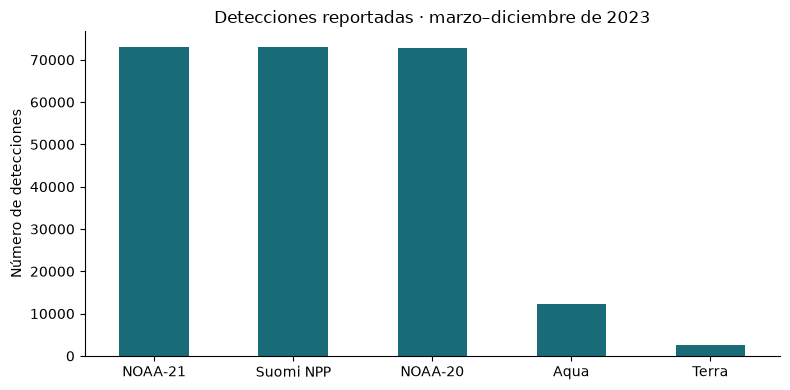

In [7]:
conteos = eda.groupby('plataforma',observed=True).size().sort_values(ascending=False)
ax = conteos.plot.bar(figsize=(8,4),color='#186b77',rot=0)
ax.set(title='Detecciones reportadas · marzo–diciembre de 2023',ylabel='Número de detecciones',xlabel='')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

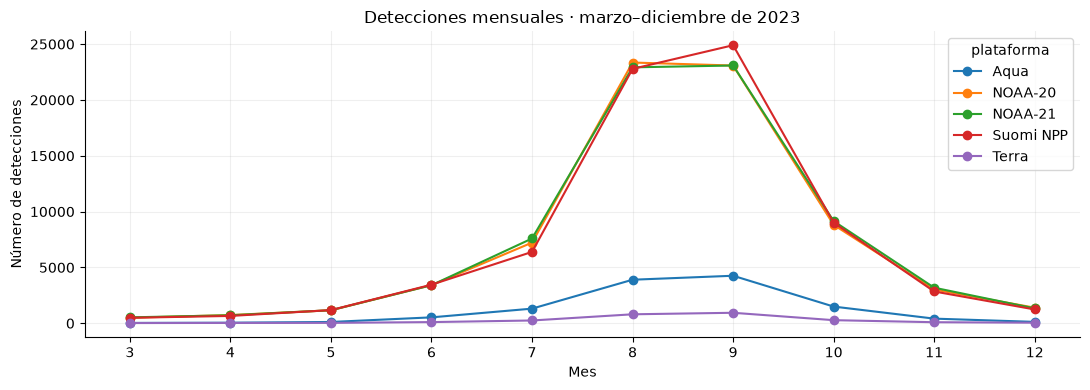

In [8]:
mensual = (eda.groupby(['mes','plataforma'],observed=True).size()
           .unstack('plataforma').reindex(range(3,13)))
ax = mensual.plot(figsize=(11,4),marker='o')
ax.set(title='Detecciones mensuales · marzo–diciembre de 2023',xlabel='Mes',ylabel='Número de detecciones',xticks=range(3,13))
ax.grid(alpha=.2)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()
mensual.to_csv(outputs/'detecciones_mensuales.csv')

Gaps stay NA. The chart describes the original counts and is not
a harmonized series. The shared period does not guarantee equal observational coverage.

## Spatial distribution
A random sample of up to 50,000 records is shown to avoid saturation.
The chart is a cloud of coordinates, with no base map or administrative boundaries.
The points do not represent fire perimeters or burned area.

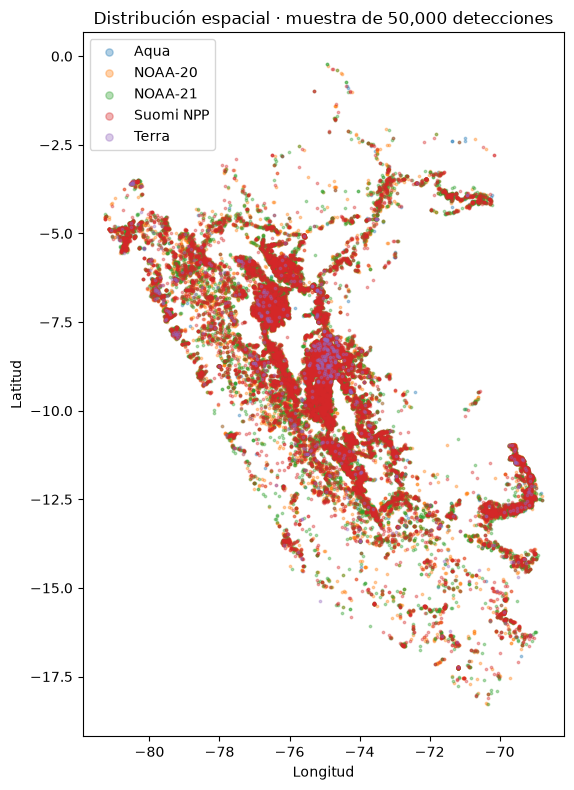

In [9]:
muestra = eda.sample(n=min(50_000,len(eda)),random_state=42)
fig, ax = plt.subplots(figsize=(8,8))
for plataforma,grupo in muestra.groupby('plataforma',observed=True):
    ax.scatter(grupo.longitude,grupo.latitude,s=3,alpha=.35,label=plataforma)
ax.set(title=f'Distribución espacial · muestra de {len(muestra):,} detecciones',xlabel='Longitud',ylabel='Latitud')
ax.set_aspect(1/np.cos(np.radians(muestra.latitude.mean())))
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

## Day and night
D means a daytime observation and N a night-time one. These are detection counts: they do not show
how many valid overpasses each platform had, nor that the fire started at that time.

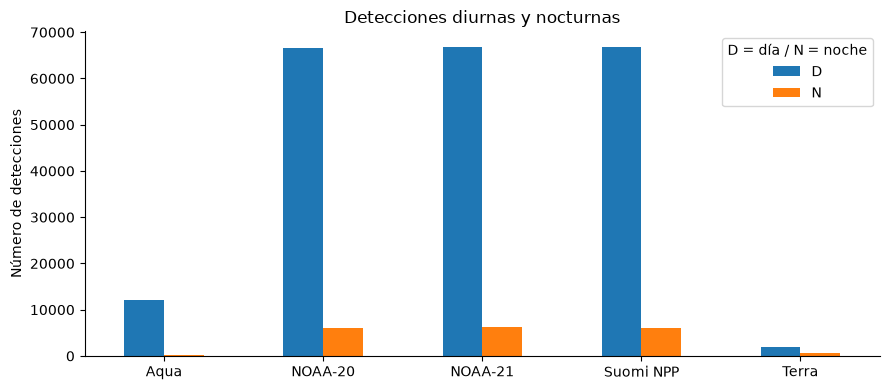

In [10]:
dia_noche = pd.crosstab(eda.plataforma,eda.daynight)
ax = dia_noche.plot.bar(figsize=(9,4),rot=0)
ax.set(title='Detecciones diurnas y nocturnas',ylabel='Número de detecciones',xlabel='')
ax.legend(title='D = día / N = noche')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()
dia_noche.to_csv(outputs/'dia_noche.csv')

## Confidence and fire radiative power (FRP)
MODIS confidence is numeric and VIIRS uses l/n/h. They are explored separately and not
converted into the same probability. FRP is given in MW: it is not hectares
burned or total energy. Its summaries do not correct differences between instruments.

In [11]:
for fuente,grupo in eda.groupby('fuente',observed=True):
    print('\n'+str(fuente))
    display(grupo.confidence.value_counts().rename_axis('confianza').to_frame('detecciones'))
frp_resumen = eda.groupby('plataforma',observed=True).frp.describe(
    percentiles=[.25,.50,.75,.95]).round(2)
display(frp_resumen)
frp_resumen.to_csv(outputs/'frp_resumen.csv')


MODIS


,detecciones
confianza,
0,430
66,390
75,373
71,370
72,359
...,...
10,4
8,3
9,3



VIIRS NOAA-20


,detecciones
confianza,
n,65100
l,4456
h,3134



VIIRS NOAA-21


,detecciones
confianza,
n,65129
l,4629
h,3321



VIIRS Suomi NPP


,detecciones
confianza,
n,65427
l,4425
h,3099


,count,mean,std,min,25%,50%,75%,95%,max
plataforma,,,,,,,,,
Aqua,12233.0,30.69,49.65,2.50,9.90,16.80,32.30,96.90,1480.70
NOAA-20,72690.0,10.29,17.19,0.06,3.47,5.82,10.60,31.89,574.38
NOAA-21,73079.0,11.83,20.15,0.00,4.06,6.79,12.30,35.11,672.69
Suomi NPP,72951.0,10.35,16.46,0.07,3.54,5.87,10.62,33.62,510.79
Terra,2613.0,22.01,99.89,3.10,7.80,12.30,21.50,57.40,3820.00


## Scope summary
Inventory and quality use all the files. The activity charts and summaries
are limited to the 2023 exploratory period, without using 2024–2025.
No harmonization, training or imputation of observational zeros was applied.
The originals were kept; each record keeps its source file.

In [12]:
manifest = {'zip_sha256':hashes,'total_rows':len(df),'eda_rows':len(eda),
            'eda_start_utc':INICIO,'eda_end_exclusive_utc':FIN_EXCLUSIVO,
            'processing':'Histórico','type':0,'confidence_filter_applied':False,
            'reserved_years_explored':False,'harmonized':False,
            'random_spatial_sample_rows':len(muestra),'random_seed':42}
(outputs/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('EDA terminado. Datos originales preservados; gráficos y tablas ejecutados.')

EDA terminado. Datos originales preservados; gráficos y tablas ejecutados.
